# 03. 상담 예제 2 — "해외송금이 아직 도착하지 않았어요" (tool retry loop)

두 번째 상담 예제입니다. 이번에는 질문에 정보가 충분하지만(송금 번호·금액 포함), **첫 번째 tool이 시스템 오류(tool_error)를 반환**합니다. agent는 D6(tool 결과 검토)에서 오류를 읽고 `try_alternative`를 판정해 **다른 tool로 재시도**하는 recursive loop를 돕니다.

예상 경로:
```
D1 -> D2(transfers) -> D5(info_sufficient) -> D3(track_transfer) -> tool_error
-> D6(try_alternative) -> D3(대체 tool, 실패 tool 제외) -> 성공 -> D6(goal_met)
-> 요약 -> D7(no_risk) -> D4(resolve) -> 최종 응답
```

실제 운영에서 흔한 "일시 오류 -> 자동 복구" 흐름입니다. 재시도 loop가 돌면 판단 횟수가 9회까지 늘어나므로 판단 latency의 누적 효과가 더 잘 보입니다.

In [1]:
import sys; sys.path.insert(0, "/home/ubuntu/LLMRouter/OpenSource/workshop")  # ws_common 경로
import ws_common as W
graphs, client = W.make_graphs()
sc = W.SCENARIOS[2]
print("시나리오:", sc["title"])
print("고객 질문:", sc["question"])
print("script:", sc["script"])   # tool_outcomes: [tool_error, success]

시나리오: 시스템 오류 -> tool retry loop
고객 질문: 어제 오후에 보낸 해외송금이 아직 수취인에게 도착하지 않았어요. 송금 번호는 TR-20261026-8841, 금액은 USD 2,000입니다. 확인해 주세요.
script: {'vague': False, 'clarify_reply': None, 'no_info_reply': '지금 알려드릴 수 있는 정보는 그게 전부예요.', 'tool_outcomes': ['tool_error', 'success'], 'risk_flag': False, 'kyc_result': None}


## 전체 workflow에서 이 시나리오의 위치

이번 시나리오가 지나는 경로(빨간 테두리): 되묻기 없이 바로 tool로 진행하지만, 첫 tool이 실패해 **tool_step의 self-loop(재시도)** 를 한 바퀴 돕니다. 같은 노드가 두 번 실행되는 것을 STEP 출력에서 확인하세요.

배정 상담팀(빨간 표시): **transfers(이체/송금)** — 해외송금 추적이므로 transfers 팀 tool(track_transfer 등)로 처리됩니다.
> 참고: 이 다이어그램은 실행되는 LangGraph에서 자동 생성된 것이 아니라, `ws_common.py`의 한글 캡션 사전(`KO_NODES`/`KO_EDGES`)을 노드 이름 기준으로 그린 **시각화 전용 그림**입니다 (상세 설명: `01_build_agent.ipynb` 참조).


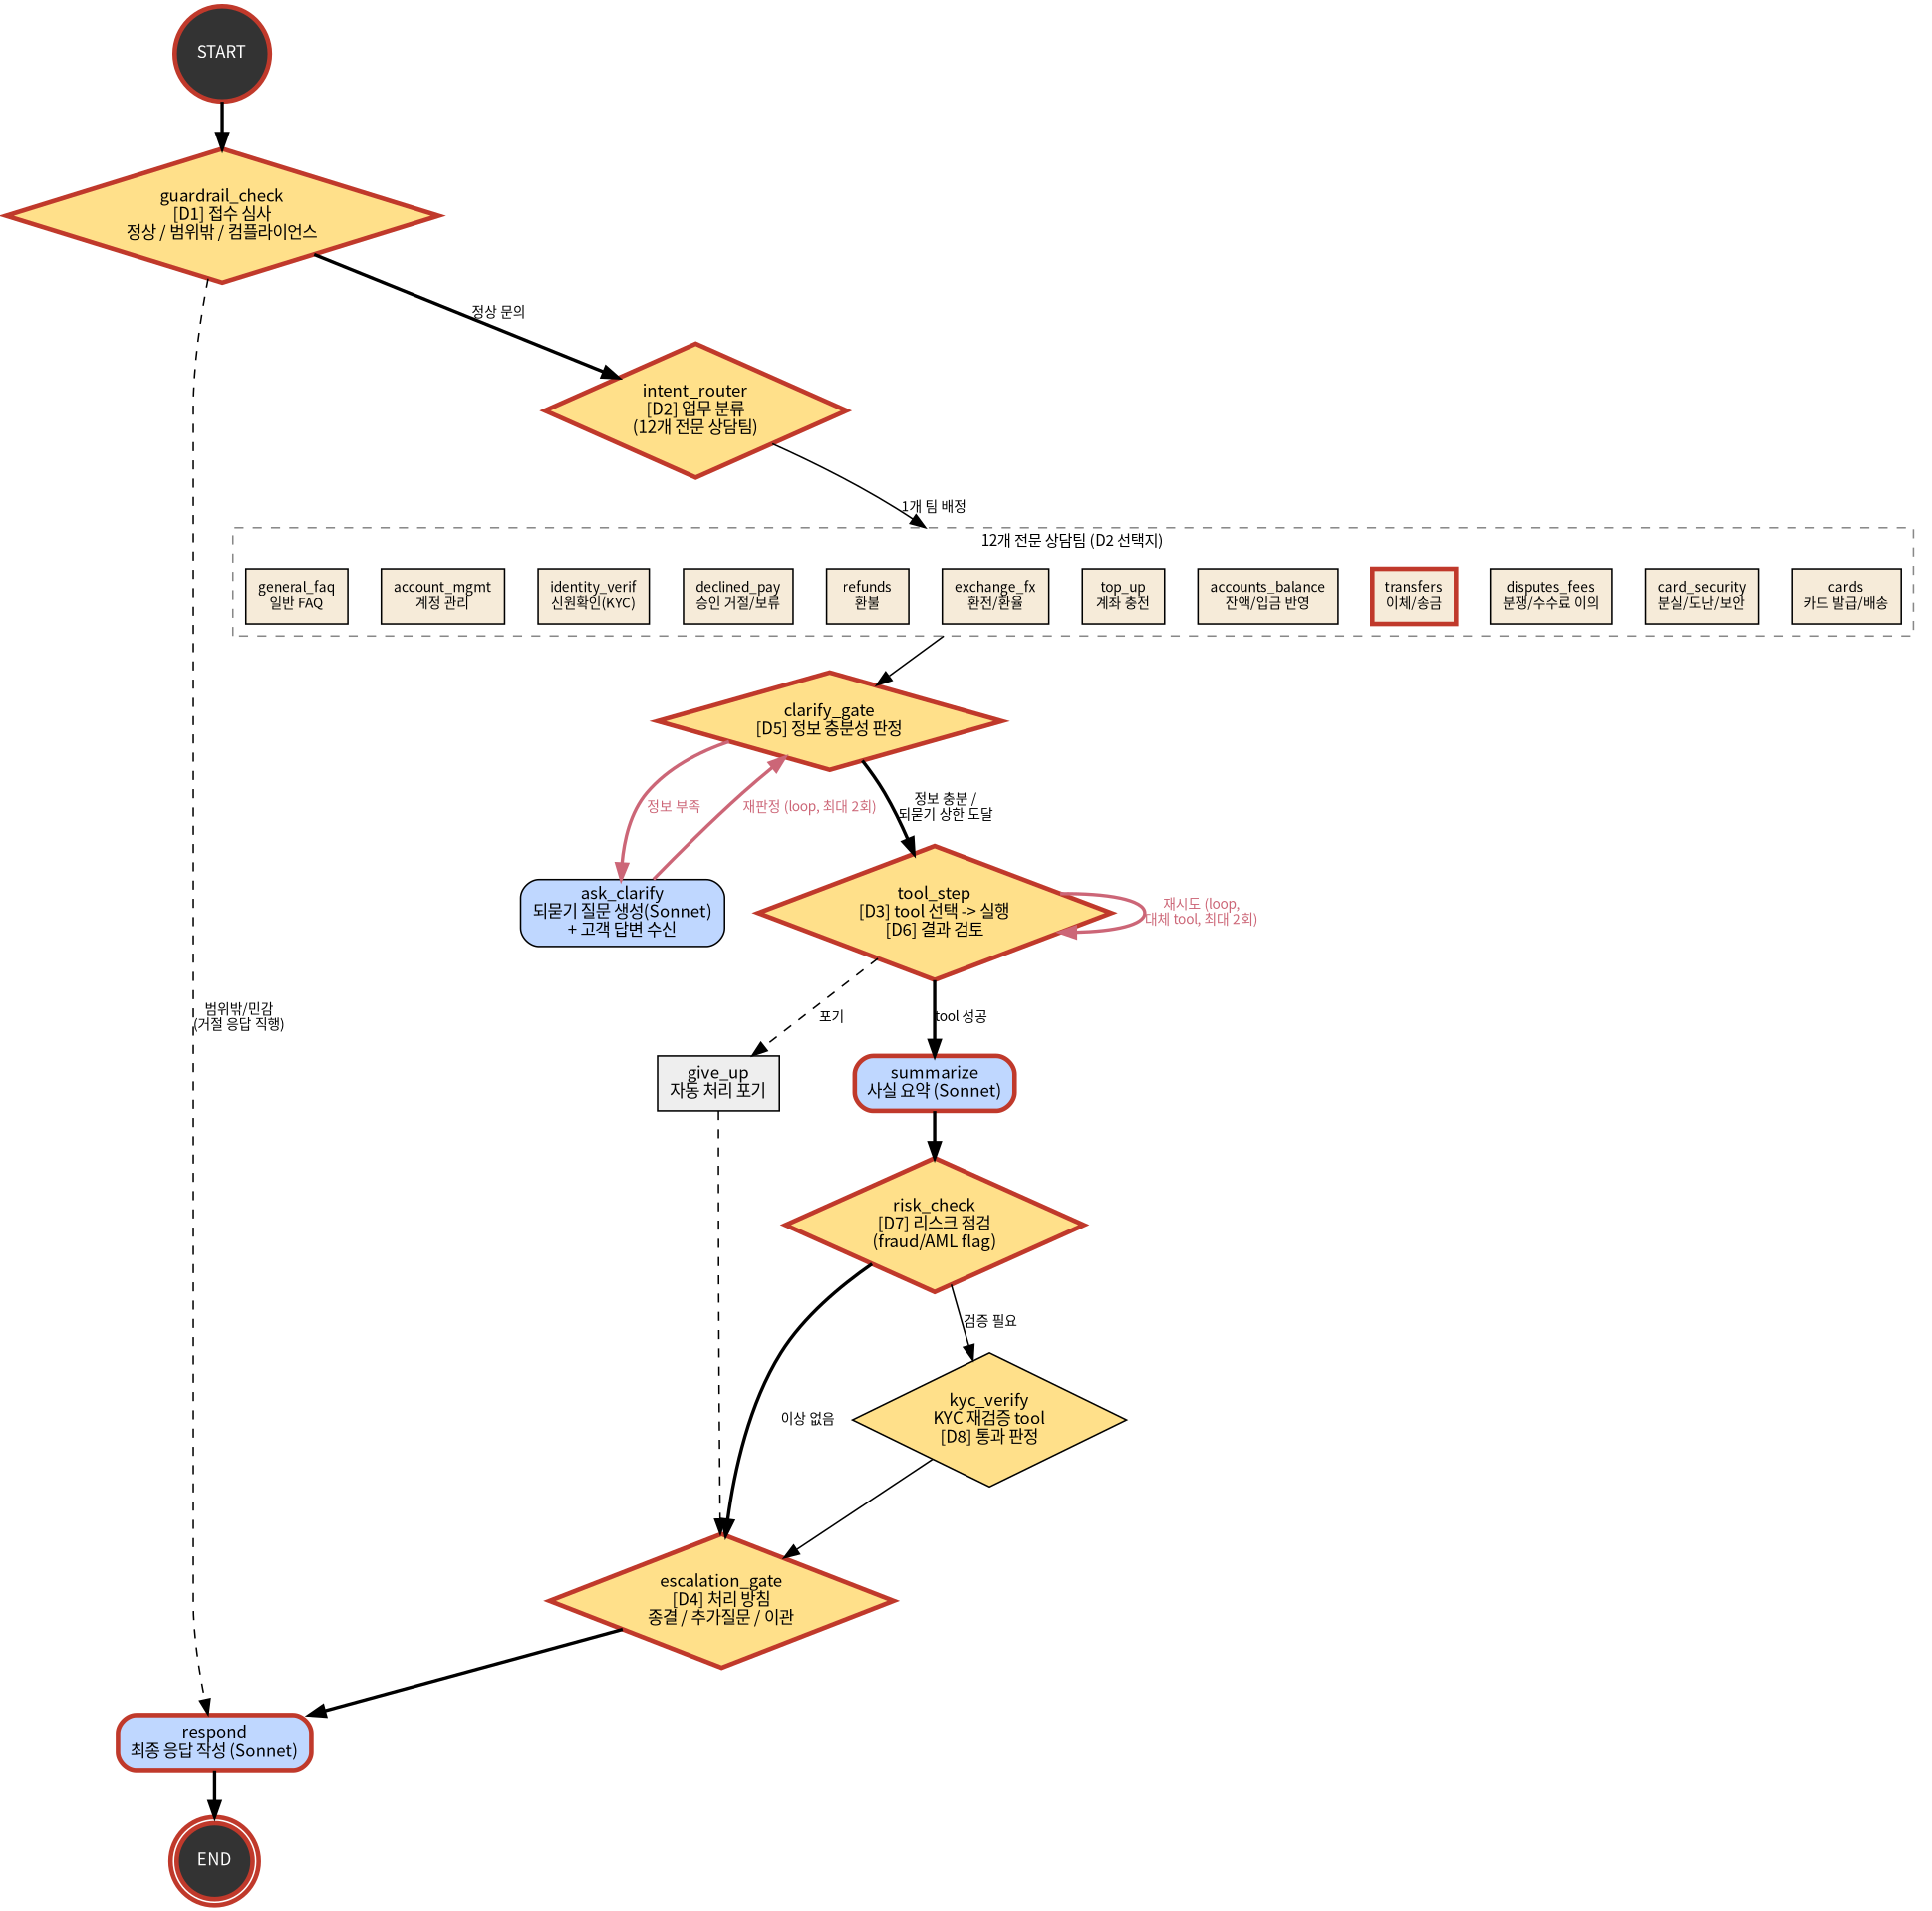

In [2]:
W.draw_graph(highlight=W.SCENARIO_PATHS[2], show_teams=True, width=760)

## ① Haiku 4.5 판단으로 실행

STEP 출력에서 tool_step이 **두 번** 나타나는 것(실패 -> 대체 tool 재시도)과, 두 번째 D3 판정 때 "Already tried (failed)" 정보가 반영되는 것을 확인하세요.

In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] 고객: 어제 오후에 보낸 해외송금이 아직 수취인에게 도착하지 않았어요. 송금 번호는 TR-20261026-8841, 금액은 USD 2,000입니다. 확인해 주세요.



STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (912ms)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> transfers   (611ms)



STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (650ms)



STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> track_transfer   (658ms)
      tool 실행: track_transfer   (0.0ms)
      판정[D6] -> try_alternative   (615ms)



STEP 5 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> transfer_info   (598ms)
      tool 실행: transfer_info   (0.0ms)
      판정[D6] -> goal_met   (630ms)



STEP 6 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (5,087ms)
      요약(첫 줄): Based on the tool result, I cannot extract specific resolution facts because the



STEP 7 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> no_risk   (666ms)



STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> human_handoff   (659ms)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (4,358ms)
      --- 최종 응답 ---
      고객님, 안녕하세요.
      
      해외송금 건(TR-20261026-8841)에 대해 문의해 주셔서 감사합니다. 현재 시스템에서 해당 송금의 상세 처리 상태를 확인하기 위해 전문 상담원에게 케이스를 전달했습니다.
      
      전문 상담원이 송금 진행 상황, 지연 사유, 예상 도착 시간 등을 상세히 확인하여 영업일 기준 1~2일 내에 직접 연락드릴 예정입니다.
      
      불편을 드려 죄송하며, 신속한 처리를 위해 최선을 다하겠습니다.
      
      감사합니다.

>>> [Haiku] 결정 9회 합계 6,000ms | 생성 9,445ms | e2e 15,454ms


## ② SGLang(Qwen3-VL-8B) 판단으로 실행

In [4]:
res_sglang = W.run_verbose(graphs["SGLang"], sc["question"], sc["script"], "SGLang")


[SGLang] 고객: 어제 오후에 보낸 해외송금이 아직 수취인에게 도착하지 않았어요. 송금 번호는 TR-20261026-8841, 금액은 USD 2,000입니다. 확인해 주세요.

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (53ms, confidence 1.000)

STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> transfers   (34ms, confidence 1.000)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (34ms, confidence 1.000)

STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> track_transfer   (33ms, confidence 1.000)
      tool 실행: track_transfer   (0.0ms)
      판정[D6] -> try_alternative   (35ms, confidence 1.000)



STEP 5 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> transfer_info   (32ms, confidence 1.000)
      tool 실행: transfer_info   (0.0ms)
      판정[D6] -> goal_met   (34ms, confidence 0.996)



STEP 6 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (5,179ms)
      요약(첫 줄): Based on the tool result provided, I cannot extract specific resolution facts ab

STEP 7 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> no_risk   (39ms, confidence 1.000)

STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> clarify   (36ms, confidence 1.000)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (5,716ms)
      --- 최종 응답 ---
      안녕하세요,
      
      송금 번호 TR-20261026-8841에 대한 조회를 진행했으나, 현재 시스템에서 상세한 송금 상태 정보를 확인할 수 없습니다.
      
      정확한 확인을 위해 다음 정보를 추가로 알려주시겠습니까?
      
      • 송금하신 **수취인 은행명**과 **국가**
      • 송금 시 등록하신 **수취인 성함**
      • 해외송금을 신청하신 **정확한 시간**(가능하다면)
      
      이 정보를 주시면 송금 진행 상황과 예상 도착 시간을 보다 정확히 안내해 드리겠습니다.
      
      감사합니다.

>>> [SGLang] 결정 9회 합계 331ms | 생성 10,896ms | e2e 11,233ms


## ③ 수행시간 비교

In [5]:
W.compare(res_haiku, res_sglang)

| 지표 | Haiku | SGLang | 배수(Haiku/SGLang) |
|---|---:|---:|---:|
| 결정 횟수 | 9 | 9 | |
| **결정 latency 합계** | **6,000ms** | **331ms** | **18.2x** |
| 생성(LLM) latency | 9,445ms | 10,896ms | **0.9x** |
| e2e | 15,454ms | 11,233ms | **1.4x** |

**결정 계층 속도 차이: 18.2x** (e2e 단축 4,221ms)

**결정별 latency**

| 노드 | 결정 | Haiku | SGLang | 배수 | 판정 label |
|---|---|---:|---:|---:|---|
| guardrail_check | D1 | 912ms | 53ms | **17.2x** | in_scope (동일) |
| intent_router | D2 | 611ms | 34ms | **18.0x** | transfers (동일) |
| clarify_gate | D5 | 650ms | 34ms | **19.4x** | info_sufficient (동일) |
| tool_select | D3 | 658ms | 33ms | **19.9x** | track_transfer (동일) |
| tool_review | D6 | 615ms | 35ms | **17.7x** | try_alternative (동일) |
| tool_select | D3 | 598ms | 32ms | **18.5x** | transfer_info (동일) |
| tool_review | D6 | 630ms | 34ms | **18.3x** | goal_met (동일) |
| risk_check | D7 | 666ms | 39ms | **16.9x** | no_risk (동일) |
| escalation_gate | D4 | 659ms | 36ms | **18.4x** | Haiku=human_handoff / SGLang=clarify |

**관찰 포인트**
- D6은 "tool의 JSON 결과를 읽고 상황을 판단"하는 결정입니다 — 분류보다 어려운 유형인데도 두 backend가 같은 결론(try_alternative -> goal_met)에 도달했는지 확인하세요.
- 판단이 9회로 늘면서 Haiku arm의 판단 누적 시간이 5-6초에 달합니다. loop가 많은 agent일수록 decision layer의 가치가 커지는 이유입니다.
- 다음: `04_scenario3_risk_kyc.ipynb` — 이상거래 모니터링 flag와 KYC 재검증 sub-flow.